# Decision Tree V2

For V2, I wanted to see how changing the maximum depth would affect the Decision Tree. I kept the same training and validation samples as V1 and compared a few different depths on both datasets.

First, I imported the libraries and functions I'll need.

In [1]:
from pathlib import Path
from time import perf_counter
import sys

import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from src.data_loader import load_task, split_train_val
from src.models.decision_tree import DecisionTreeClassifier

depths = [2, 3, 5, 8]
result_dir = project_root / "results" / "decision_tree"
v1_summary = pd.read_csv(result_dir / "decision_tree_v1_summary.csv")


I started by testing the different depths on the image dataset.

In [2]:
X, y, _, _ = load_task("image")
X_train, X_val, y_train, y_val = split_train_val(X, y, val_fraction=0.2, seed=42)
image_X_train = X_train[:200]
image_y_train = y_train[:200]
image_X_val = X_val[:200]
image_y_val = y_val[:200]
assert image_X_train.shape == (200, 500)
assert image_X_val.shape == (200, 500)
v1_validation = pd.read_csv(result_dir / "decision_tree_v1_image_validation.csv")
v1_result = v1_summary.loc[v1_summary["dataset"] == "image"].iloc[0]
assert v1_validation["validation_index"].tolist() == list(range(200))
assert v1_validation["actual_label"].tolist() == image_y_val.tolist()

image_rows = []
image_models = {}
image_validation_predictions = {}
for depth in depths:
    clf = DecisionTreeClassifier(max_depth=depth, min_samples=1)
    print(f"Fitting image: depth={depth}, 200 training samples, 500 features")
    start = perf_counter()
    clf.fit(image_X_train, image_y_train)
    fit_time = perf_counter() - start
    training_accuracy = clf.score(image_X_train, image_y_train)
    start = perf_counter()
    y_pred = clf.predict(image_X_val)
    prediction_time = perf_counter() - start
    validation_accuracy = sum(p == t for p, t in zip(y_pred, image_y_val)) / len(image_y_val)
    image_models[depth] = clf
    image_validation_predictions[depth] = y_pred
    if depth == 3:
        assert training_accuracy == v1_result["training_accuracy"] == 0.145
        assert validation_accuracy == v1_result["validation_accuracy"] == 0.045
        assert y_pred == v1_validation["predicted_label"].tolist()
        print("Depth 3 reproduces V1 accuracies and all validation predictions exactly.")
    image_rows.append({
        "dataset": "image",
        "version": "V2",
        "criterion": "entropy",
        "max_depth": depth,
        "min_samples": clf.min_samples,
        "normalized": False,
        "training_samples": len(image_X_train),
        "validation_samples": len(image_X_val),
        "training_accuracy": training_accuracy,
        "validation_accuracy": validation_accuracy,
        "fit_time_seconds": fit_time,
        "prediction_time_seconds": prediction_time,
    })
    print(f"Depth={depth}, training={training_accuracy:.2%}, validation={validation_accuracy:.2%}")
    print(f"Fit time={fit_time:.6f} s, validation prediction time={prediction_time:.6f} s")
image_summary = pd.DataFrame(image_rows)


Fitting image: depth=2, 200 training samples, 500 features
Depth=2, training=9.50%, validation=4.50%
Fit time=6.370083 s, validation prediction time=0.002414 s
Fitting image: depth=3, 200 training samples, 500 features
Depth 3 reproduces V1 accuracies and all validation predictions exactly.
Depth=3, training=14.50%, validation=4.50%
Fit time=6.005367 s, validation prediction time=0.004454 s
Fitting image: depth=5, 200 training samples, 500 features
Depth=5, training=34.00%, validation=3.00%
Fit time=5.783212 s, validation prediction time=0.000916 s
Fitting image: depth=8, 200 training samples, 500 features
Depth=8, training=74.50%, validation=3.00%
Fit time=8.748697 s, validation prediction time=0.002653 s


Then I repeated the same experiment with the sentiment dataset.

In [3]:
X, y, _, _ = load_task("sentiment")
X_train, X_val, y_train, y_val = split_train_val(X, y, val_fraction=0.2, seed=42)
sentiment_X_train = X_train[:200]
sentiment_y_train = y_train[:200]
sentiment_X_val = X_val[:200]
sentiment_y_val = y_val[:200]
assert sentiment_X_train.shape == (200, 768)
assert sentiment_X_val.shape == (200, 768)
v1_validation = pd.read_csv(result_dir / "decision_tree_v1_sentiment_validation.csv")
v1_result = v1_summary.loc[v1_summary["dataset"] == "sentiment"].iloc[0]
assert v1_validation["validation_index"].tolist() == list(range(200))
assert v1_validation["actual_label"].tolist() == sentiment_y_val.tolist()

sentiment_rows = []
sentiment_models = {}
sentiment_validation_predictions = {}
for depth in depths:
    clf = DecisionTreeClassifier(max_depth=depth, min_samples=1)
    print(f"Fitting sentiment: depth={depth}, 200 training samples, 768 features")
    start = perf_counter()
    clf.fit(sentiment_X_train, sentiment_y_train)
    fit_time = perf_counter() - start
    training_accuracy = clf.score(sentiment_X_train, sentiment_y_train)
    start = perf_counter()
    y_pred = clf.predict(sentiment_X_val)
    prediction_time = perf_counter() - start
    validation_accuracy = sum(p == t for p, t in zip(y_pred, sentiment_y_val)) / len(sentiment_y_val)
    sentiment_models[depth] = clf
    sentiment_validation_predictions[depth] = y_pred
    if depth == 3:
        assert training_accuracy == v1_result["training_accuracy"] == 0.675
        assert validation_accuracy == v1_result["validation_accuracy"] == 0.45
        assert y_pred == v1_validation["predicted_label"].tolist()
        print("Depth 3 reproduces V1 accuracies and all validation predictions exactly.")
    sentiment_rows.append({
        "dataset": "sentiment",
        "version": "V2",
        "criterion": "entropy",
        "max_depth": depth,
        "min_samples": clf.min_samples,
        "normalized": False,
        "training_samples": len(sentiment_X_train),
        "validation_samples": len(sentiment_X_val),
        "training_accuracy": training_accuracy,
        "validation_accuracy": validation_accuracy,
        "fit_time_seconds": fit_time,
        "prediction_time_seconds": prediction_time,
    })
    print(f"Depth={depth}, training={training_accuracy:.2%}, validation={validation_accuracy:.2%}")
    print(f"Fit time={fit_time:.6f} s, validation prediction time={prediction_time:.6f} s")
sentiment_summary = pd.DataFrame(sentiment_rows)


Fitting sentiment: depth=2, 200 training samples, 768 features
Depth=2, training=60.50%, validation=42.00%
Fit time=29.482380 s, validation prediction time=0.000497 s
Fitting sentiment: depth=3, 200 training samples, 768 features
Depth 3 reproduces V1 accuracies and all validation predictions exactly.
Depth=3, training=67.50%, validation=45.00%
Fit time=26.521578 s, validation prediction time=0.001160 s
Fitting sentiment: depth=5, 200 training samples, 768 features
Depth=5, training=93.00%, validation=44.00%
Fit time=35.699669 s, validation prediction time=0.006286 s
Fitting sentiment: depth=8, 200 training samples, 768 features
Depth=8, training=100.00%, validation=44.00%
Fit time=41.743522 s, validation prediction time=0.002082 s


I plotted the training and validation accuracies to compare the different depths.

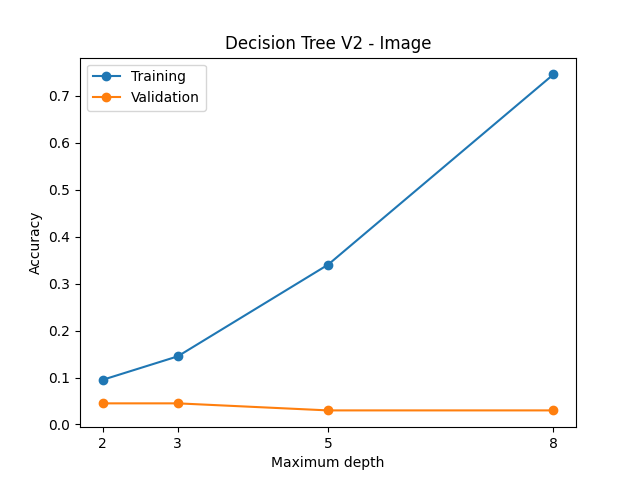

In [4]:
plt.figure()
plt.plot(depths, image_summary["training_accuracy"], marker="o", label="Training")
plt.plot(depths, image_summary["validation_accuracy"], marker="o", label="Validation")
plt.xlabel("Maximum depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree V2 - Image")
plt.xticks(depths)
plt.legend()
plt.savefig(result_dir / "decision_tree_v2_image_depth.png")
plt.show()


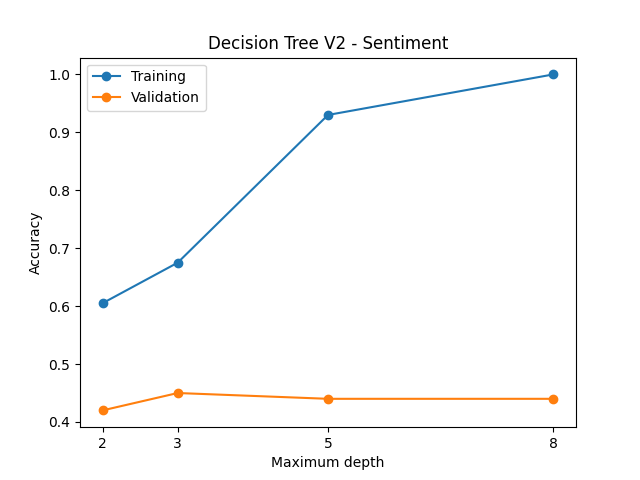

In [5]:
plt.figure()
plt.plot(depths, sentiment_summary["training_accuracy"], marker="o", label="Training")
plt.plot(depths, sentiment_summary["validation_accuracy"], marker="o", label="Validation")
plt.xlabel("Maximum depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree V2 - Sentiment")
plt.xticks(depths)
plt.legend()
plt.savefig(result_dir / "decision_tree_v2_sentiment_depth.png")
plt.show()


Finally, I compared the validation results to choose the best depth for each dataset.

In [6]:
image_best_accuracy = -1
for row in image_rows:
    # Depths are ascending, so the smaller depth wins an accuracy tie.
    if row["validation_accuracy"] > image_best_accuracy:
        image_best_depth = row["max_depth"]
        image_best_accuracy = row["validation_accuracy"]
print(f"Image: selected depth={image_best_depth}, validation accuracy={image_best_accuracy:.2%}")
pd.DataFrame({
    "validation_index": range(len(image_y_val)),
    "actual_label": image_y_val,
    "predicted_label": image_validation_predictions[image_best_depth],
}).to_csv(result_dir / "decision_tree_v2_image_validation.csv", index=False)

sentiment_best_accuracy = -1
for row in sentiment_rows:
    # Depths are ascending, so the smaller depth wins an accuracy tie.
    if row["validation_accuracy"] > sentiment_best_accuracy:
        sentiment_best_depth = row["max_depth"]
        sentiment_best_accuracy = row["validation_accuracy"]
print(f"Sentiment: selected depth={sentiment_best_depth}, validation accuracy={sentiment_best_accuracy:.2%}")
pd.DataFrame({
    "validation_index": range(len(sentiment_y_val)),
    "actual_label": sentiment_y_val,
    "predicted_label": sentiment_validation_predictions[sentiment_best_depth],
}).to_csv(result_dir / "decision_tree_v2_sentiment_validation.csv", index=False)

summary = pd.DataFrame(image_rows + sentiment_rows)
assert len(summary) == 8
summary.to_csv(result_dir / "decision_tree_v2_summary.csv", index=False)
print(summary.to_string(index=False))


Image: selected depth=2, validation accuracy=4.50%
Sentiment: selected depth=3, validation accuracy=45.00%
  dataset version criterion  max_depth  min_samples  normalized  training_samples  validation_samples  training_accuracy  validation_accuracy  fit_time_seconds  prediction_time_seconds
    image      V2   entropy          2            1       False               200                 200              0.095                0.045          6.370083                 0.002414
    image      V2   entropy          3            1       False               200                 200              0.145                0.045          6.005367                 0.004454
    image      V2   entropy          5            1       False               200                 200              0.340                0.030          5.783212                 0.000916
    image      V2   entropy          8            1       False               200                 200              0.745                0.030          8.

In [7]:
tracker_path = result_dir / "kaggle_scores.csv"
tracker = pd.read_csv(tracker_path, dtype=str, keep_default_na=False)
assert tracker["version"].is_unique
v2_row = {
    "version": "V2",
    "image_validation_accuracy": image_best_accuracy,
    "sentiment_validation_accuracy": sentiment_best_accuracy,
    "kaggle_public_score": "",
    "submitted_to_kaggle": False,
    "submission_filename": "",
    "notes": f"Tested max_depth=2, 3, 5, 8; selected image depth={image_best_depth}, sentiment depth={sentiment_best_depth}; min_samples=1, 200 training samples per dataset, entropy.",
}
matching = tracker["version"] == "V2"
if matching.any():
    for column in ("image_validation_accuracy", "sentiment_validation_accuracy", "submission_filename", "notes"):
        tracker.loc[matching, column] = v2_row[column]
else:
    tracker = pd.concat([tracker, pd.DataFrame([v2_row])], ignore_index=True)
assert tracker["version"].is_unique
tracker.to_csv(tracker_path, index=False)
print(tracker.to_string(index=False))


version image_validation_accuracy sentiment_validation_accuracy kaggle_public_score submitted_to_kaggle submission_filename                                                                                                                             notes
     V1                     0.045                          0.45                                   False                                                              max_depth=3, min_samples=1; 200 training examples per dataset; entropy/information gain.
     V2                     0.045                          0.45                                   False                     Tested max_depth=2, 3, 5, 8; selected image depth=2, sentiment depth=3; min_samples=1, 200 training samples per dataset, entropy.


I kept depth 2 for image after the tie and depth 3 for sentiment. Going beyond depth 3 increased training accuracy but lowered validation accuracy on both datasets.